# Vibration analysis of square steel bars

The measurements are compared in the time domain and in the frequency domain. The files contain time, acceleration, and a third channel; only time and acceleration are used here.

In [7]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

plt.style.use("seaborn-v0_8-whitegrid")
DATA = Path("../Lab_1/data")


def read_measurement(filename):
    # The first line is measurement metadata, so skip it.
    values = np.loadtxt(filename, delimiter=";", skiprows=1, usecols=(0, 1))
    return values[:, 0], values[:, 1]


files = {
    "Intact": sorted((DATA / "Not_damaged_specimen").glob("*.csv")),
    "Sawn": sorted((DATA / "Damaged_specimen").glob("*.csv")),
}

print({name: len(group_files) for name, group_files in files.items()})
print(files)


{'Intact': 4, 'Sawn': 4}
{'Intact': [PosixPath('../Lab_1/data/Not_damaged_specimen/Not_damaged_1.csv'), PosixPath('../Lab_1/data/Not_damaged_specimen/Not_damaged_2.csv'), PosixPath('../Lab_1/data/Not_damaged_specimen/Not_damaged_3.csv'), PosixPath('../Lab_1/data/Not_damaged_specimen/Not_damaged_4.csv')], 'Sawn': [PosixPath('../Lab_1/data/Damaged_specimen/Damaged_1.csv'), PosixPath('../Lab_1/data/Damaged_specimen/Damaged_2.csv'), PosixPath('../Lab_1/data/Damaged_specimen/Damaged_3.csv'), PosixPath('../Lab_1/data/Damaged_specimen/Damaged_4.csv')]}


## Time signals

Each subplot shows one complete measurement. The acceleration offset is removed only for plotting and spectral analysis.

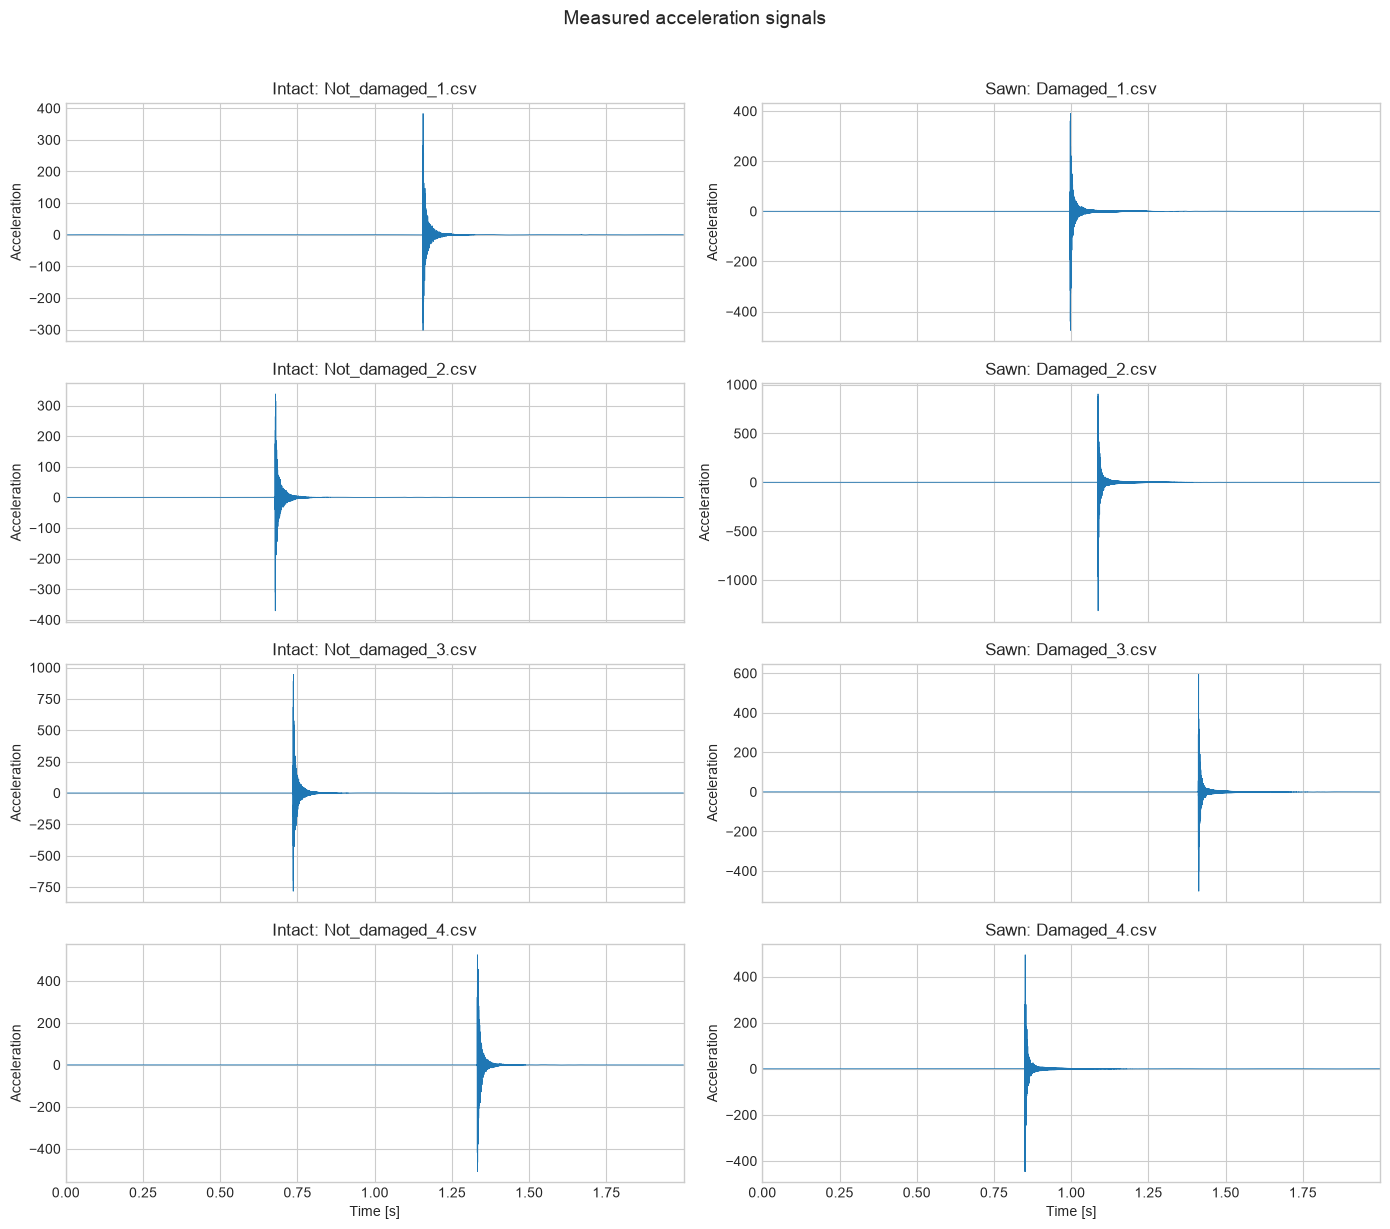

In [8]:
fig, axes = plt.subplots(4, 2, figsize=(14, 12), sharex=True)

for row, (intact_file, sawn_file) in enumerate(zip(files["Intact"], files["Sawn"])):
    for column, (label, filename) in enumerate(
        (("Intact", intact_file), ("Sawn", sawn_file))
    ):
        time, acceleration = read_measurement(filename)
        axes[row, column].plot(time, acceleration, linewidth=0.6)
        axes[row, column].set_title(f"{label}: {filename.stem}.csv")
        axes[row, column].set_ylabel("Acceleration")
        axes[row, column].set_xlim(time[0], time[-1])

axes[-1, 0].set_xlabel("Time [s]")
axes[-1, 1].set_xlabel("Time [s]")
fig.suptitle("Measured acceleration signals", y=1.02, fontsize=14)
fig.tight_layout()
plt.show()

## Spectra

The one-sided FFT amplitude spectrum shows which vibration frequencies contain most of the signal energy. The DC component is removed before calculating the FFT.

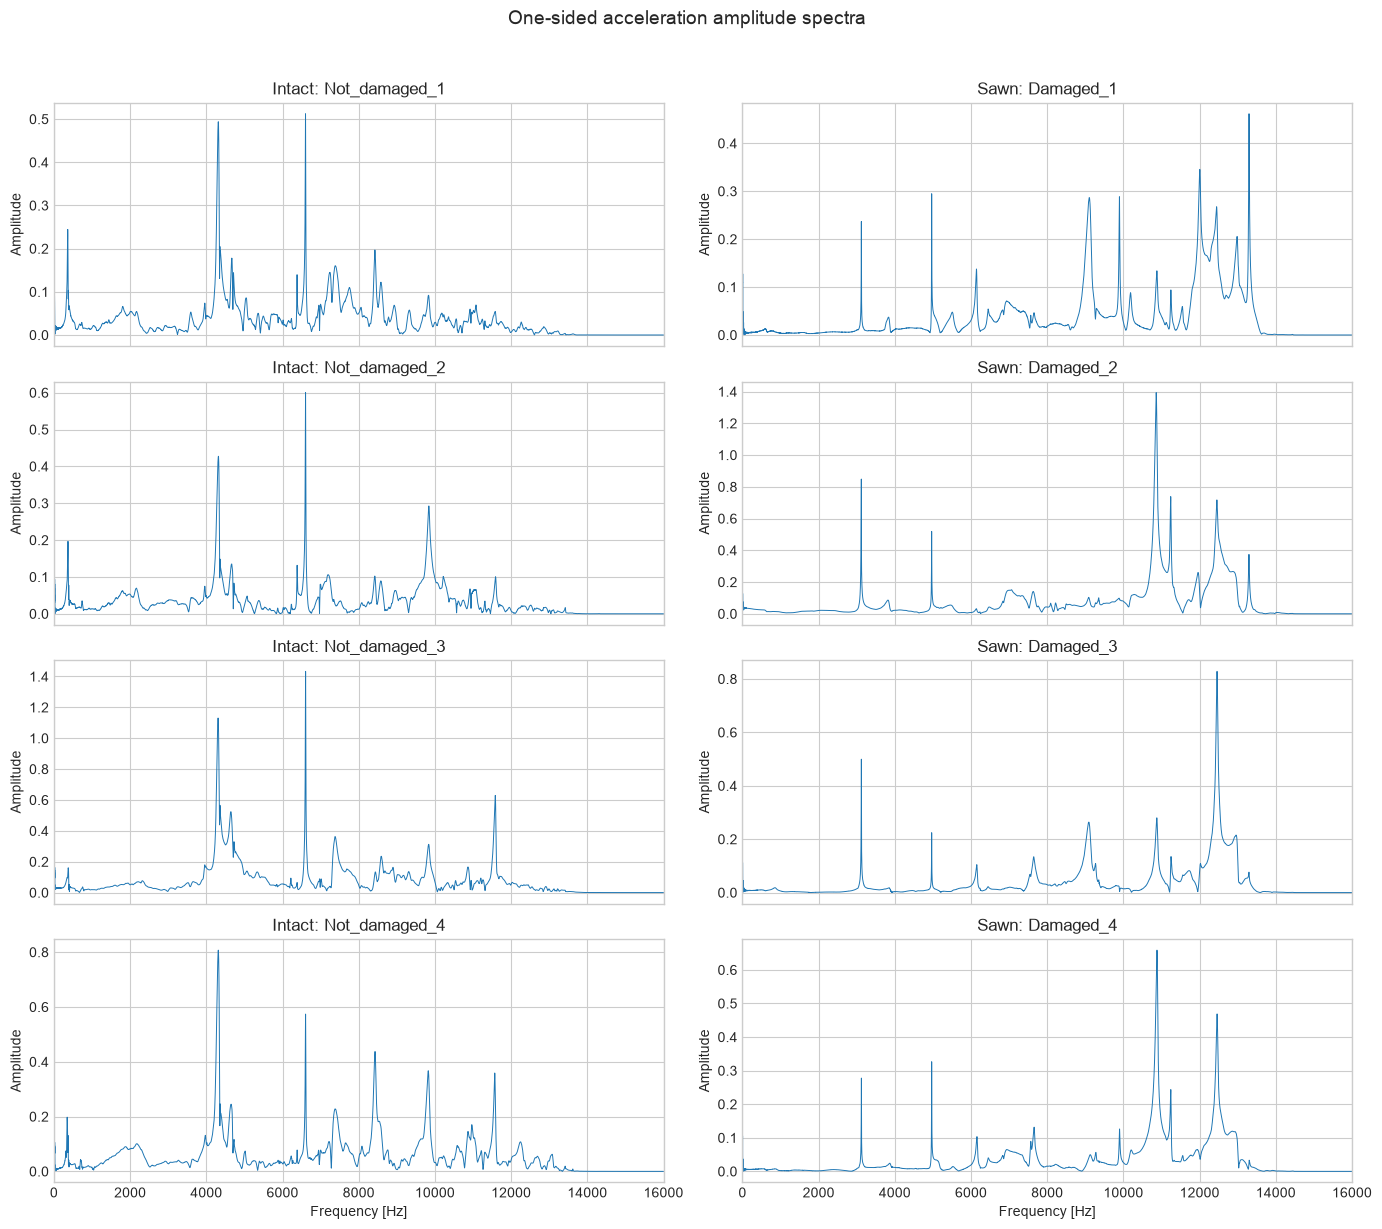

In [9]:
def spectrum(time, acceleration):
    sample_time = np.median(np.diff(time))
    #sample_rate = 1 / sample_time
    signal = acceleration - np.mean(acceleration)
    frequencies = np.fft.rfftfreq(signal.size, d=sample_time)
    amplitudes = 2 * np.abs(np.fft.rfft(signal)) / signal.size
    amplitudes[0] /= 2
    return frequencies, amplitudes


fig, axes = plt.subplots(4, 2, figsize=(14, 12), sharex=True)

for row, (intact_file, sawn_file) in enumerate(zip(files["Intact"], files["Sawn"])):
    for column, (label, filename) in enumerate(
        (("Intact", intact_file), ("Sawn", sawn_file))
    ):
        time, acceleration = read_measurement(filename)
        frequency, amplitude = spectrum(time, acceleration)
        axes[row, column].plot(frequency, amplitude, linewidth=0.7)
        axes[row, column].set_title(f"{label}: {filename.stem}")
        axes[row, column].set_ylabel("Amplitude")
        axes[row, column].set_xlim(0, 16000)

axes[-1, 0].set_xlabel("Frequency [Hz]")
axes[-1, 1].set_xlabel("Frequency [Hz]")
fig.suptitle("One-sided acceleration amplitude spectra", y=1.02, fontsize=14)
fig.tight_layout()
plt.show()

## Distinguishing intact and sawn bars

A simple feature is the frequency of the largest non-zero FFT peak. It is more useful here than the overall amplitude because the impact strength varies between measurements.

Specimen              File  RMS acceleration  Dominant frequency [Hz]  Peak amplitude
  Intact Not_damaged_1.csv             7.176                 6602.987           0.512
  Intact Not_damaged_2.csv             7.099                 6604.004           0.600
  Intact Not_damaged_3.csv            17.235                 6605.021           1.433
  Intact Not_damaged_4.csv            11.978                 4313.660           0.807
    Sawn     Damaged_1.csv             8.152                13297.017           0.462
    Sawn     Damaged_2.csv            18.907                10860.189           1.393
    Sawn     Damaged_3.csv            10.087                12457.784           0.828
    Sawn     Damaged_4.csv             8.809                10881.042           0.659


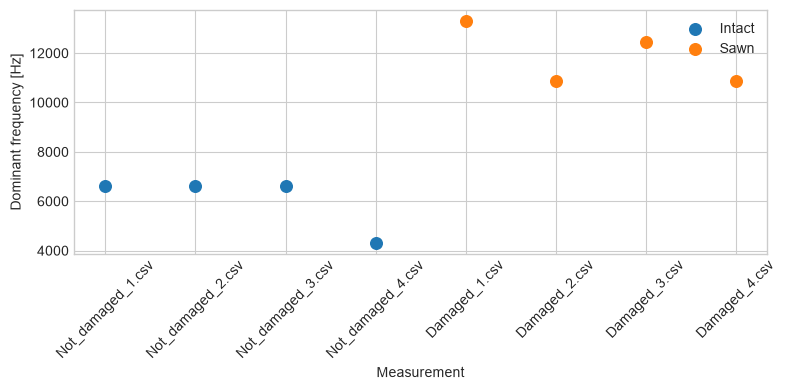

In [10]:
results = []
for label, group_files in files.items():
    for filename in group_files:
        time, acceleration = read_measurement(filename)
        frequency, amplitude = spectrum(time, acceleration)
        peak_index = np.argmax(amplitude[1:]) + 1
        results.append(
            {
                "Specimen": label,
                "File": filename.name,
                "RMS acceleration": np.sqrt(
                    np.mean((acceleration - acceleration.mean()) ** 2)
                ),
                "Dominant frequency [Hz]": frequency[peak_index],
                "Peak amplitude": amplitude[peak_index],
            }
        )

summary = pd.DataFrame(results)
print(summary.round(3).to_string(index=False))

fig, ax = plt.subplots(figsize=(8, 4))
for label, data in summary.groupby("Specimen"):
    ax.scatter(data["File"], data["Dominant frequency [Hz]"], label=label, s=70)
ax.set_ylabel("Dominant frequency [Hz]")
ax.set_xlabel("Measurement")
ax.tick_params(axis="x", rotation=45)
ax.legend()
fig.tight_layout()
plt.show()

### Conclusion

The intact and sawn bars can be distinguished by their dominant resonance frequencies. In these measurements, the intact specimens have dominant peaks near 0, 4.3 kHz, or 6.6 kHz, while the sawn specimens have peaks near 4.9 kHz, 10.9 kHz, 12.5 kHz, or 13.3 kHz. Therefore, the spectrum (especially the peak locations) is a useful damage indicator. The signal amplitude alone should not be used as the only criterion because it depends strongly on the impact strength and sensor coupling.

For a larger dataset, a threshold or a small classifier could be trained using several spectral peaks, RMS value, and peak amplitudes. The present separation is a visual/feature-based distinction, not a generalised classifier.